# Практическая работа № 1

**Линейные дискретные системы и преобразование Фурье**

Вариант 15  
Спиридонов Александр Натанович  
Группа 3381

## Цель работы

Изучить линейную дискретную систему, рассчитать её характеристики и реакцию
на прямоугольный импульс. Выполнить ДПФ последовательности из двух гармоник
и восстановить исходный сигнал по спектру.

## Выполнение работы

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

np.set_printoptions(precision=6, suppress=True)
plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

variant = 15

## Часть 1. Линейная дискретная система

Передаточная функция системы:

$$H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}}.$$

Для варианта 15 коэффициенты и параметры равны:

$$b_0=0.8,\quad b_1=0.99936,\quad b_2=0.64,$$
$$a_0=1,\quad a_1=-1.1528,\quad a_2=0.73,$$
$$N_1=25,\quad N_2=35,\quad f_д=15000\ \text{Гц}.$$

In [ ]:
b0 = 0.5 + 0.02*variant
b = np.array([b0, b0*(-1)**(variant+1)*(0.9822+0.0178*variant),
              b0*(0.8+0.2*(variant % 5))])
a = np.array([1, (-1)**variant*(0.7778+0.025*variant), 0.64+0.006*variant])
N1 = variant % 10 + 20
N2 = variant % 10 + 30
fd1 = 1000*variant

print('b =', b)
print('a =', a)
print(f'N₁ = {N1}, N₂ = {N2}, fд = {fd1} Гц')

b = [0.8     0.99936 0.64   ]
a = [ 1.     -1.1528  0.73  ]
N₁ = 25, N₂ = 35, fд = 15000 Гц


### 1. Импульсная характеристика

Импульсная характеристика — реакция на единичный импульс $\delta[n]$
при $h[-1]=h[-2]=0$:

$$h[n]=0.8\delta[n]+0.99936\delta[n-1]+0.64\delta[n-2]
+1.1528h[n-1]-0.73h[n-2].$$

Для полюсов $p_1,p_2$ формула без рекурсии имеет вид

$$h[n]=b_0\delta[n]+(R_1p_1^{n-1}+R_2p_2^{n-1})u[n-1],$$

где $u[n]$ — единичная ступенька,

$$R_1=\frac{p_1(b_1-a_1b_0)+b_2-a_2b_0}{p_1-p_2},\qquad R_2=R_1^*.$$

В нашем случае:

$$h[0]=0.8,$$
$$h[n]=2.663936019\cdot0.854400375^{n-1}
\cos(0.830339529(n-1)-0.765063116),\quad n\ge1.$$

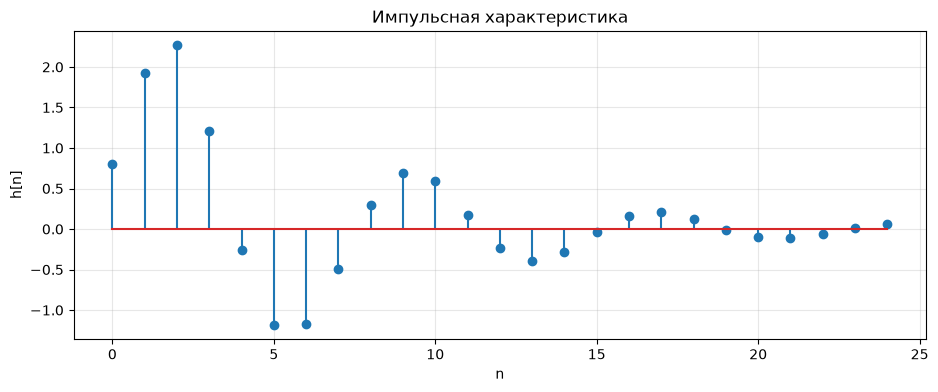

Первые отсчёты h[n]: [ 0.8       1.9216    2.27122   1.215495 -0.256768 -1.183314 -1.176683
 -0.492661]


In [ ]:
impulse = np.zeros(N1)
impulse[0] = 1
h = signal.lfilter(b, a, impulse)

poles = np.roots(a)
p1 = poles[np.argmax(poles.imag)]
p2 = np.conj(p1)
R1 = (p1*(b[1]-a[1]*b[0])+b[2]-a[2]*b[0])/(p1-p2)
n_h = np.arange(N1)
h_formula = np.empty(N1)
h_formula[0] = b[0]
h_formula[1:] = 2*abs(R1)*abs(p1)**(n_h[1:]-1)*np.cos(
    (n_h[1:]-1)*np.angle(p1)+np.angle(R1))

plt.figure()
plt.stem(n_h, h)
plt.xlabel('n')
plt.ylabel('h[n]')
plt.title('Импульсная характеристика')
plt.show()
print('Первые отсчёты h[n]:', h[:8])
assert np.allclose(h, h_formula, atol=1e-12)

На графике показаны первые 25 отсчётов. Истинная импульсная характеристика
бесконечна: обратная связь создаёт затухающие колебания, которые продолжаются
и после $n=24$. Длина $N_1=25$ относится только к рассчитанному фрагменту.

### 2. Реакция по формуле свёртки

При округлении $N_2/2=17.5$ до ближайшего целого получаем 18:

$$x[n]=\begin{cases}1,&0\le n\le17,\\0,&18\le n\le34.\end{cases}$$

Реакцию вычисляем по формуле

$$y_1[n]=\sum_{m=0}^{24}h[m]x[n-m].$$

Массив воздействия содержит 35 отсчётов, из которых 18 ненулевых.
Длительность прямоугольного импульса равна $18/f_д=1.2$ мс.

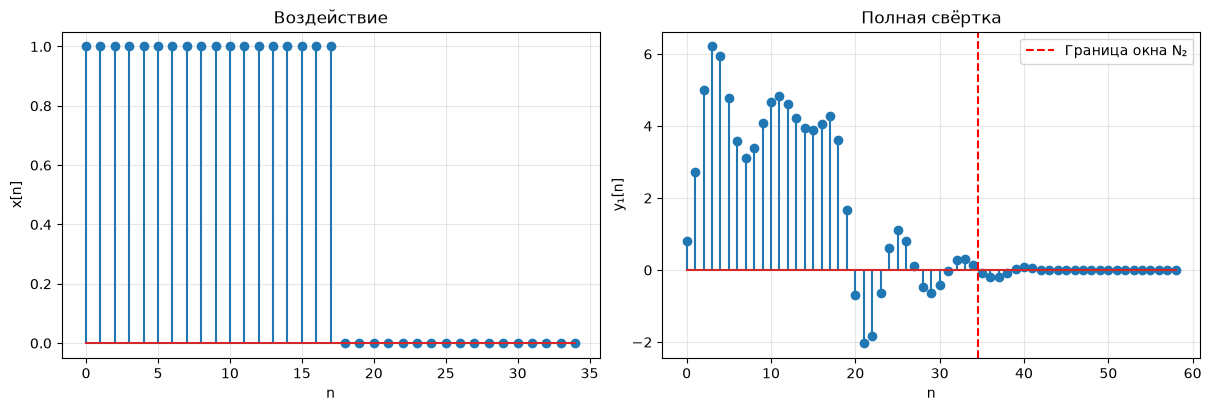

Длина массива свёртки: 59
Последний ненулевой отсчёт: n = 41


In [ ]:
M = int(np.floor(N2/2+0.5))
n_x = np.arange(N2)
x_rect = (n_x < M).astype(float)
y1_full = np.convolve(x_rect, h)
y1 = y1_full[:N2]

fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax[0].stem(n_x, x_rect)
ax[0].set(xlabel='n', ylabel='x[n]', title='Воздействие')
ax[1].stem(np.arange(len(y1_full)), y1_full)
ax[1].axvline(N2-0.5, color='red', linestyle='--', label='Граница окна N₂')
ax[1].set(xlabel='n', ylabel='y₁[n]', title='Полная свёртка')
ax[1].legend()
plt.show()

last_nonzero = np.flatnonzero(abs(y1_full)>1e-12)[-1]
print('Длина массива свёртки:', len(y1_full))
print('Последний ненулевой отсчёт: n =', last_nonzero)
assert len(y1_full) == 59 and last_nonzero == 41

Длина полной свёртки массивов равна $N_1+N_2-1=25+35-1=59$.
Из-за нулевой второй части входа ненулевые значения заканчиваются при $n=41$;
это видно на графике. Ненулевая часть занимает 42 позиции.

Для сравнения с разностным уравнением используем первые 35 отсчётов реакции.

### 3. Реакция по разностному уравнению

Разностное уравнение с коэффициентами варианта 15:

$$y[n]=0.8x[n]+0.99936x[n-1]+0.64x[n-2]
+1.1528y[n-1]-0.73y[n-2].$$

Принимаем нулевые начальные условия: $x[n]=y[n]=0$ при $n<0$.

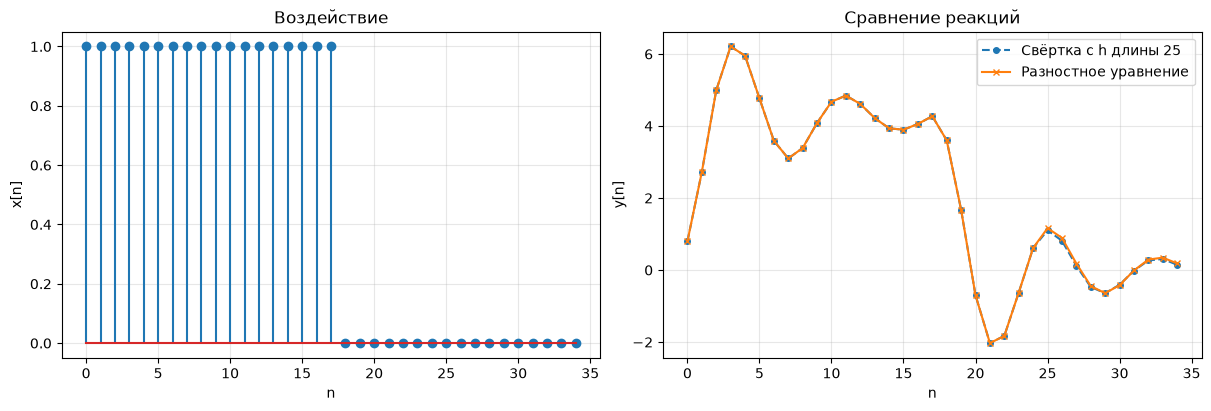

Разница с усечённой h: 0.0796197942913488
Разница при длине h = N₂: 2.3314683517128287e-15


In [ ]:
def system_response(x, b, a):
    y = np.zeros(len(x))
    for n in range(len(x)):
        for i in range(len(b)):
            if n >= i:
                y[n] += b[i]*x[n-i]
        for k in range(1, len(a)):
            if n >= k:
                y[n] -= a[k]*y[n-k]
        y[n] /= a[0]
    return y

y2 = system_response(x_rect, b, a)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax[0].stem(n_x, x_rect)
ax[0].set(xlabel='n', ylabel='x[n]', title='Воздействие')
ax[1].plot(n_x, y1, 'o--', markersize=4, label='Свёртка с h длины 25')
ax[1].plot(n_x, y2, 'x-', markersize=4, label='Разностное уравнение')
ax[1].set(xlabel='n', ylabel='y[n]', title='Сравнение реакций')
ax[1].legend()
plt.show()

# Достаточная длина h для проверки совпадения на всём исходном окне.
impulse_check = np.zeros(N2)
impulse_check[0] = 1
h_check = signal.lfilter(b, a, impulse_check)
y_check = np.convolve(x_rect, h_check)[:N2]
print('Разница с усечённой h:', np.max(abs(y2-y1)))
print('Разница при длине h = N₂:', np.max(abs(y2-y_check)))
assert np.allclose(y2, signal.lfilter(b, a, x_rect), atol=1e-12)
assert np.max(abs(y2-y_check)) < 1e-12
assert np.max(abs(y2[:N1]-y1[:N1])) < 1e-12

Длины рассчитанных массивов воздействия и реакции равны 35.
Истинная реакция системы имеет бесконечный затухающий хвост.

Результаты совпадают на первых 25 отсчётах, далее свёртка с коротким фрагментом
$h[n]$ немного отличается от рекурсии, поскольку хвост импульсной характеристики
отброшен.
Максимальная разница равна примерно 0.07962.
При расчёте $h[n]$ длины 35 оба метода совпадают на всём выбранном интервале.

### 4. Нули и полюса передаточной функции

Умножив числитель и знаменатель на $z^2$, получаем

$$H(z)=\frac{0.8z^2+0.99936z+0.64}{z^2-1.1528z+0.73}.$$

Нули - корни числителя, полюса - корни знаменателя.
Для перехода от алгебраической формы $z=x+jy$ к показательной используем

$$z=|z|e^{j\varphi},\qquad |z|=\sqrt{x^2+y^2},\qquad
\varphi=\operatorname{atan2}(y,x).$$

In [ ]:
zeros = np.roots(b)
print('Нули:', zeros)
print('Полюса:', poles)
for name, roots in [('Нуль', zeros), ('Полюс', poles)]:
    for root in roots:
        print(f'{name}: модуль = {abs(root):.6f}; аргумент = {np.angle(root)/np.pi:.6f}π')

Нули: [-0.6246+0.640215j -0.6246-0.640215j]
Полюса: [0.5764+0.630685j 0.5764-0.630685j]
Нуль: модуль = 0.894427; аргумент = 0.746071π
Нуль: модуль = 0.894427; аргумент = -0.746071π
Полюс: модуль = 0.854400; аргумент = 0.264305π
Полюс: модуль = 0.854400; аргумент = -0.264305π


Алгебраическая и показательная формы:

$$z_{1,2}=-0.6246\pm j0.640215
=0.894427e^{\pm j0.746071\pi},$$
$$p_{1,2}=0.5764\pm j0.630685
=0.854400e^{\pm j0.264305\pi}.$$

Передаточная функция в виде произведения множителей (значения округлены):

$$H(z)=0.8\frac{
(1-0.894427e^{j0.746071\pi}z^{-1})(1-0.894427e^{-j0.746071\pi}z^{-1})}{
(1-0.854400e^{j0.264305\pi}z^{-1})(1-0.854400e^{-j0.264305\pi}z^{-1})}.$$

### 5. Карта нулей и полюсов

Для устойчивости причинной системы все несокращённые полюса должны находиться
внутри единичной окружности: $|p_i|<1$.

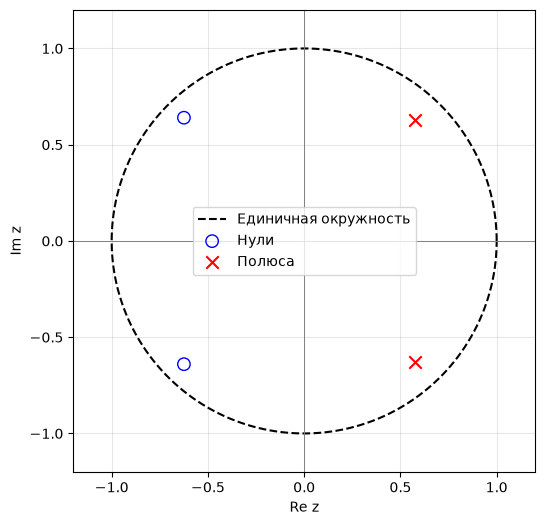

Модули полюсов: [0.8544 0.8544]
Совпадение с tf2zpk: True


In [ ]:
z_check, p_check, gain = signal.tf2zpk(b, a)
angle = np.linspace(0, 2*np.pi, 400)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(np.cos(angle), np.sin(angle), 'k--', label='Единичная окружность')
ax.scatter(zeros.real, zeros.imag, facecolors='none', edgecolors='blue', s=80, label='Нули')
ax.scatter(poles.real, poles.imag, marker='x', color='red', s=80, label='Полюса')
ax.axhline(0, color='gray', linewidth=0.7)
ax.axvline(0, color='gray', linewidth=0.7)
ax.set(xlabel='Re z', ylabel='Im z', xlim=(-1.2, 1.2), ylim=(-1.2, 1.2))
ax.set_aspect('equal')
ax.legend()
plt.show()
print('Модули полюсов:', abs(poles))
print('Совпадение с tf2zpk:', np.allclose(np.sort_complex(zeros), np.sort_complex(z_check))
      and np.allclose(np.sort_complex(poles), np.sort_complex(p_check)))
assert np.max(abs(poles)) < 1

Оба полюса находятся внутри единичного круга, их модуль равен 0.8544, - значит, система устойчива.
Координаты нулей и полюсов на карте
совпадают с результатами пункта 4, это также проверено функцией `tf2zpk`.

### 6. АЧХ и ФЧХ в нормированной шкале

Частотная характеристика получается подстановкой $z=e^{j\widehat\omega}$:

$$A(\widehat\omega)=|H(e^{j\widehat\omega})|,\qquad
\varphi(\widehat\omega)=\arg H(e^{j\widehat\omega}).$$

Основная полоса частот — $[-\pi,\pi)$ рад/отсчёт.
Характеристики повторяются с периодом $2\pi$. Для действительных коэффициентов
АЧХ чётная, поэтому достаточно также рассматривать полосу $[0,\pi]$.

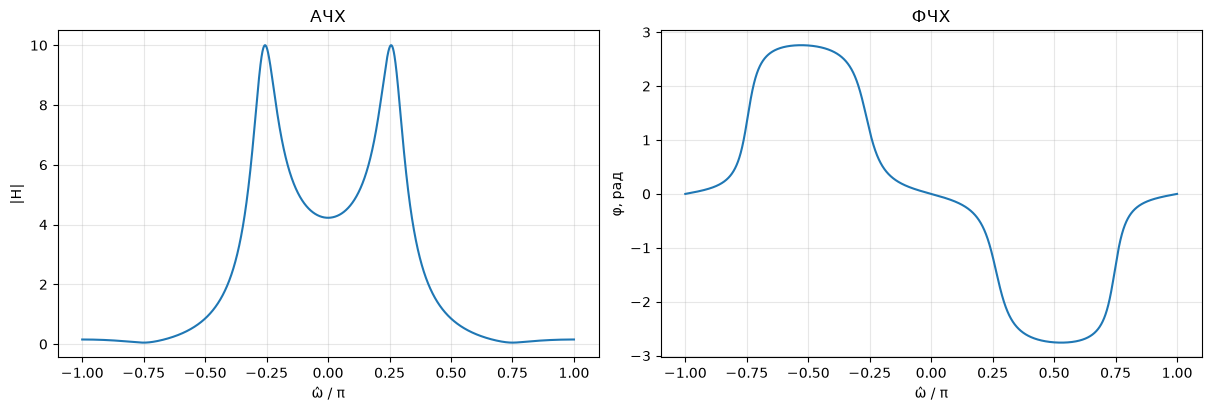

АЧХ при ω̂ = 0: 4.2262
Максимум: 10.0013, ω̂/π ≈ 0.2563
Минимум: 0.0481, ω̂/π ≈ 0.7500
АЧХ при ω̂ = π: 0.1529


In [ ]:
w = np.linspace(-np.pi, np.pi, 8193)
_, H = signal.freqz(b, a, worN=w)
amp = abs(H)
phase = np.angle(H)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax[0].plot(w/np.pi, amp)
ax[0].set(xlabel='ω̂ / π', ylabel='|H|', title='АЧХ')
ax[1].plot(w/np.pi, phase)
ax[1].set(xlabel='ω̂ / π', ylabel='φ, рад', title='ФЧХ')
plt.show()

positive_indices = np.flatnonzero(w >= 0)
i_max = positive_indices[np.argmax(amp[positive_indices])]
i_min = positive_indices[np.argmin(amp[positive_indices])]
_, H_edges = signal.freqz(b, a, worN=[0, np.pi])
print(f'АЧХ при ω̂ = 0: {abs(H_edges[0]):.4f}')
print(f'Максимум: {amp[i_max]:.4f}, ω̂/π ≈ {w[i_max]/np.pi:.4f}')
print(f'Минимум: {amp[i_min]:.4f}, ω̂/π ≈ {w[i_min]/np.pi:.4f}')
print(f'АЧХ при ω̂ = π: {abs(H_edges[1]):.4f}')

Вблизи углов полюсов АЧХ возрастает, вблизи углов нулей - уменьшается, что следует из выражения

$$|H(e^{j\widehat\omega})|=0.8\frac{
|e^{j\widehat\omega}-z_1||e^{j\widehat\omega}-z_2|}{
|e^{j\widehat\omega}-p_1||e^{j\widehat\omega}-p_2|}.$$

На положение экстремумов влияют все корни, поэтому экстремумы не обязаны
точно совпадать с их аргументами.

Скачка фазы на $\pi$ в этом варианте нет.
При пересечении простого нуля
на единичной окружности такой скачок соответствовал бы нулевому значению АЧХ.
Здесь нули лежат внутри окружности, и АЧХ не обращается в нуль.

Низкие частоты усиливаются: при нулевой частоте усиление равно 4.2262.
Высокие частоты преимущественно подавляются, особенно около
$\widehat\omega=0.75\pi$, поэтому реакция на прямоугольный импульс содержит
более плавные переходы и затухающие колебания.

### 7. АЧХ и ФЧХ в герцах

Связь нормированной и абсолютной частот:

$$\widehat\omega=\frac{2\pi f}{f_д},\qquad
f=\frac{\widehat\omega f_д}{2\pi}.$$

При $f_д=15000$ Гц основная полоса — $[-7500,7500)$ Гц,
а положительная половина — $[0,7500]$ Гц.

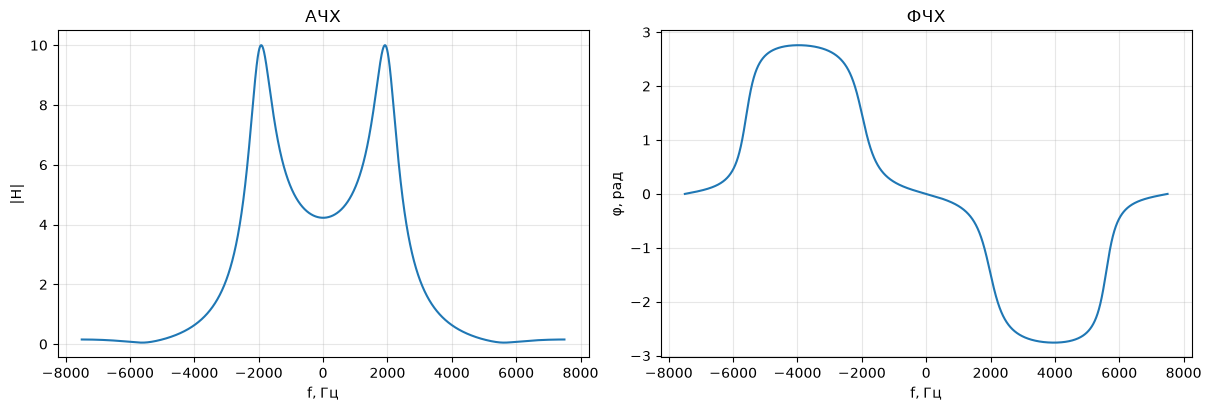

Частота максимума АЧХ ≈ 1922.6 Гц
Частота минимума АЧХ ≈ 5625.0 Гц


In [ ]:
f = w*fd1/(2*np.pi)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax[0].plot(f, amp)
ax[0].set(xlabel='f, Гц', ylabel='|H|', title='АЧХ')
ax[1].plot(f, phase)
ax[1].set(xlabel='f, Гц', ylabel='φ, рад', title='ФЧХ')
plt.show()
print(f'Частота максимума АЧХ ≈ {f[i_max]:.1f} Гц')
print(f'Частота минимума АЧХ ≈ {f[i_min]:.1f} Гц')

## Часть 2. Преобразование Фурье

Для варианта 15:

$$N=64,\quad f_д=2000\ \text{Гц},\quad T=0.0005\ \text{с},$$
$$A_1=1.15,\quad A_2=2.30,\quad f_1=250\ \text{Гц},\quad f_2=375\ \text{Гц}.$$

Исходная последовательность:

$$x[n]=1.15\cos(2\pi250nT+\pi/4)+2.30\cos(2\pi375nT+\pi/8).$$

In [ ]:
N = 64
fd = 2000*(variant % 5+1)
T = 1/fd
A1 = 1+0.01*variant
A2 = 2*A1
f1 = fd/8
f2 = 1.5*f1
n = np.arange(N)
tn = n*T
x = A1*np.cos(2*np.pi*f1*tn+np.pi/4)+A2*np.cos(2*np.pi*f2*tn+np.pi/8)
print(f'N = {N}, fд = {fd} Гц, T = {T} с')
print(f'A₁ = {A1}, A₂ = {A2}, f₁ = {f1} Гц, f₂ = {f2} Гц')

N = 64, fд = 2000 Гц, T = 0.0005 с
A₁ = 1.15, A₂ = 2.3, f₁ = 250.0 Гц, f₂ = 375.0 Гц


### 1. Графики последовательности

Дискретное физическое время равно $t_n=nT$, нормированное — $t_n/T=n$.
Строим 64 отсчёта. Они образуют период длиной $NT=32$ мс.
Минимальный период последовательности равен 16 отсчётам, поэтому
в выбранном блоке содержатся четыре минимальных периода.

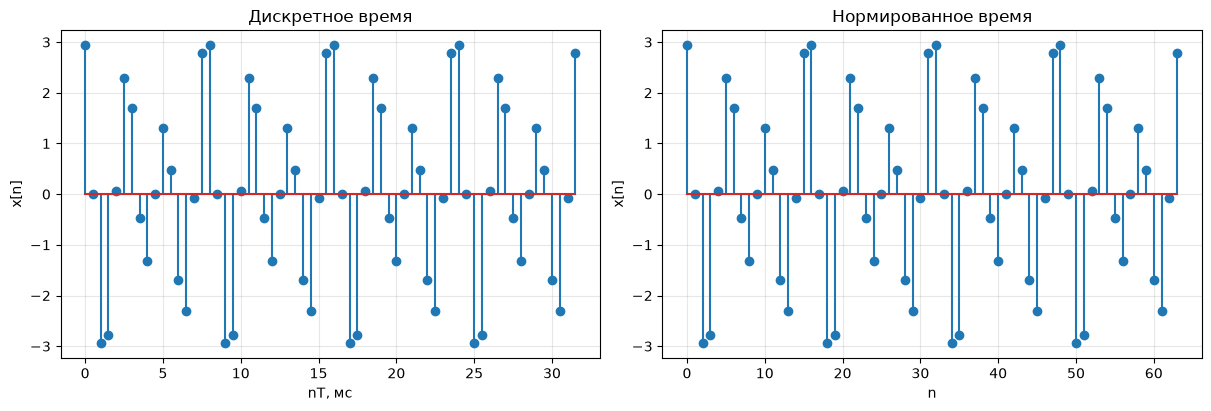

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax[0].stem(tn*1000, x)
ax[0].set(xlabel='nT, мс', ylabel='x[n]', title='Дискретное время')
ax[1].stem(n, x)
ax[1].set(xlabel='n', ylabel='x[n]', title='Нормированное время')
plt.show()
assert np.max(abs(x[16:]-x[:-16])) < 1e-12

### 2. ДПФ и обратное ДПФ

Используем формулы

$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad
x[n]=\frac1N\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}.$$

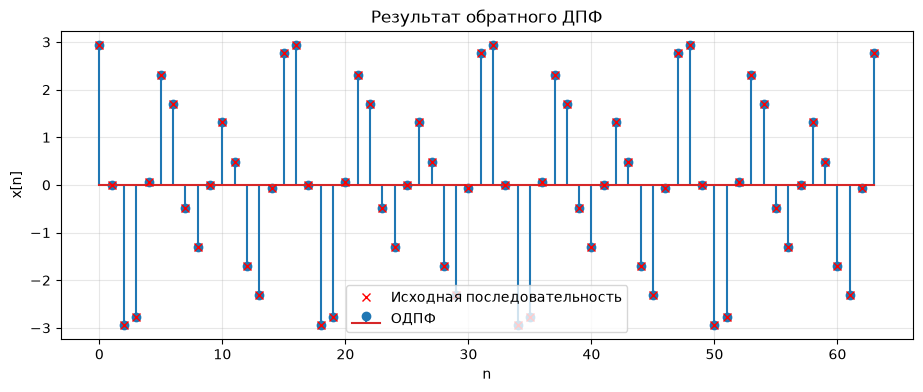

Максимальная ошибка ОДПФ: 1.350644602892852e-15


In [ ]:
X = np.fft.fft(x)
x_restored = np.fft.ifft(X)

plt.figure()
plt.stem(n, x_restored.real, label='ОДПФ')
plt.plot(n, x, 'rx', label='Исходная последовательность')
plt.xlabel('n')
plt.ylabel('x[n]')
plt.title('Результат обратного ДПФ')
plt.legend()
plt.show()

print('Максимальная ошибка ОДПФ:', np.max(abs(x-x_restored)))
X_direct = np.exp(-2j*np.pi*np.outer(n, n)/N) @ x
assert np.max(abs(X-X_direct)) < 1e-10
assert np.max(abs(x-x_restored)) < 1e-12

Полученная последовательность совпадает с исходной,
мнимая часть результата близка к нулю.

### 3. Амплитудный и фазовый спектры

Амплитудный спектр периодической последовательности равен $|X[k]|/N$,
фазовый — $\arg X[k]$ для ненулевых гармоник.

Нормированная частота $\nu=f/f_д$ связана с частотой в герцах:

$$\nu_k=\frac{k}{N},\qquad f_k=\frac{kf_д}{N},\qquad
\widehat\omega_k=2\pi\nu_k.$$

Частоты выше половины частоты дискретизации представляем как отрицательные, а фазу очень малых спектральных значений не выводим, поскольку она не определена
для нулевой амплитуды.

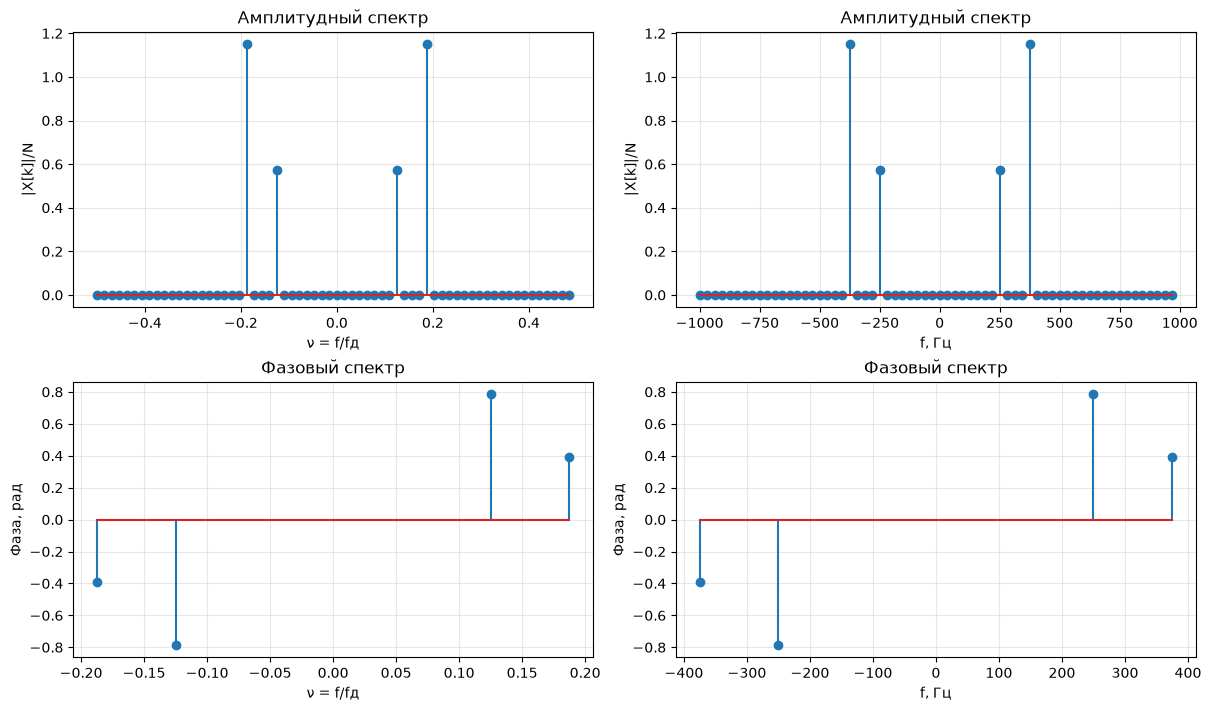

f =  -375.0 Гц; амплитуда = 1.150; фаза = -0.125π
f =  -250.0 Гц; амплитуда = 0.575; фаза = -0.250π
f =   250.0 Гц; амплитуда = 0.575; фаза = 0.250π
f =   375.0 Гц; амплитуда = 1.150; фаза = 0.125π


In [ ]:
k = np.arange(-N//2, N//2)
Xc = np.fft.fftshift(X)
nu = k/N
freq = nu*fd
amplitude = abs(Xc)/N
mask = abs(Xc) > 1e-10*np.max(abs(Xc))
phase_spectrum = np.angle(Xc)

fig, ax = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
ax[0, 0].stem(nu, amplitude)
ax[0, 0].set(xlabel='ν = f/fд', ylabel='|X[k]|/N', title='Амплитудный спектр')
ax[1, 0].stem(nu[mask], phase_spectrum[mask])
ax[1, 0].set(xlabel='ν = f/fд', ylabel='Фаза, рад', title='Фазовый спектр')
ax[0, 1].stem(freq, amplitude)
ax[0, 1].set(xlabel='f, Гц', ylabel='|X[k]|/N', title='Амплитудный спектр')
ax[1, 1].stem(freq[mask], phase_spectrum[mask])
ax[1, 1].set(xlabel='f, Гц', ylabel='Фаза, рад', title='Фазовый спектр')
plt.show()

for i in np.flatnonzero(mask):
    print(f'f = {freq[i]:7.1f} Гц; амплитуда = {amplitude[i]:.3f}; '
          f'фаза = {phase_spectrum[i]/np.pi:.3f}π')
assert set(k[mask]) == {-12, -8, 8, 12}

Оба спектра линейчатые: линии расположены на частотах $\pm250$ и $\pm375$ Гц.
Их двусторонние амплитуды равны $A_1/2=0.575$ и $A_2/2=1.15$, фазы на положительных частотах равны $\pi/4$ и $\pi/8$,
на отрицательных - $-\pi/4$ и $-\pi/8$.

Шаг частотной сетки $f_д/N=31.25$ Гц.

Гармоникам соответствуют целые
индексы $k_1=8$ и $k_2=12$.
В одностороннем спектре амплитуды положительных линий удваиваются и равны
исходным амплитудам 1.15 и 2.30.

### 4. ДПФ конечной последовательности

Для конечного блока используем те же 64 отсчёта, поэтому его ДПФ совпадает
с ДПФ одного периода.

Модуль ДПФ и амплитудный спектр периодической
последовательности отличаются нормировкой:

$$A[k]=\frac{|X[k]|}{N}.$$

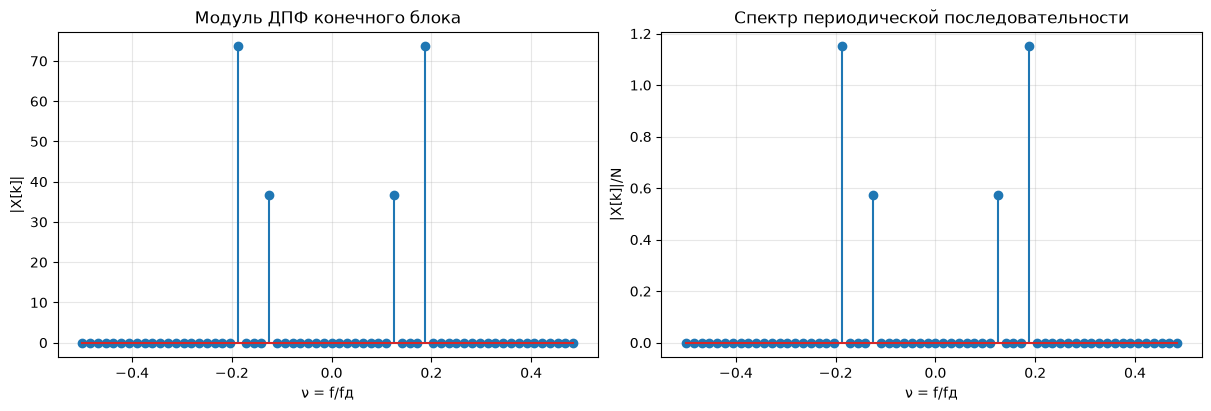

Ненулевые модули ДПФ: [73.6 36.8 36.8 73.6]


In [ ]:
X_finite = np.fft.fft(x)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax[0].stem(nu, abs(np.fft.fftshift(X_finite)))
ax[0].set(xlabel='ν = f/fд', ylabel='|X[k]|', title='Модуль ДПФ конечного блока')
ax[1].stem(nu, amplitude)
ax[1].set(xlabel='ν = f/fд', ylabel='|X[k]|/N', title='Спектр периодической последовательности')
plt.show()
print('Ненулевые модули ДПФ:', abs(Xc[mask]))
assert np.max(abs(abs(np.fft.fftshift(X_finite))-N*amplitude)) < 1e-12

Модули ненулевых коэффициентов ДПФ равны 36.8 и 73.6.
После деления на $N=64$ получаем амплитуды спектральных линий 0.575 и 1.15.

### 5. Восстановление аналогового сигнала

Используем формулу задания:

$$x(t)=\frac1N\sum_{k=-N/2}^{N/2-1}X_a[k]
\exp\left(j\frac{2\pi k}{NT}t\right),$$

$$X_a[k]=\begin{cases}X[N+k],&-N/2\le k\le-1,\\
X[k],&0\le k\le N/2-1.\end{cases}$$

Порядок $X_a[k]$ получаем с помощью `fftshift`.
Время изменяется от 0 до $(N-1)T=31.5$ мс с шагом
$\Delta t=T/4=0.125$ мс, всего 253 точки.

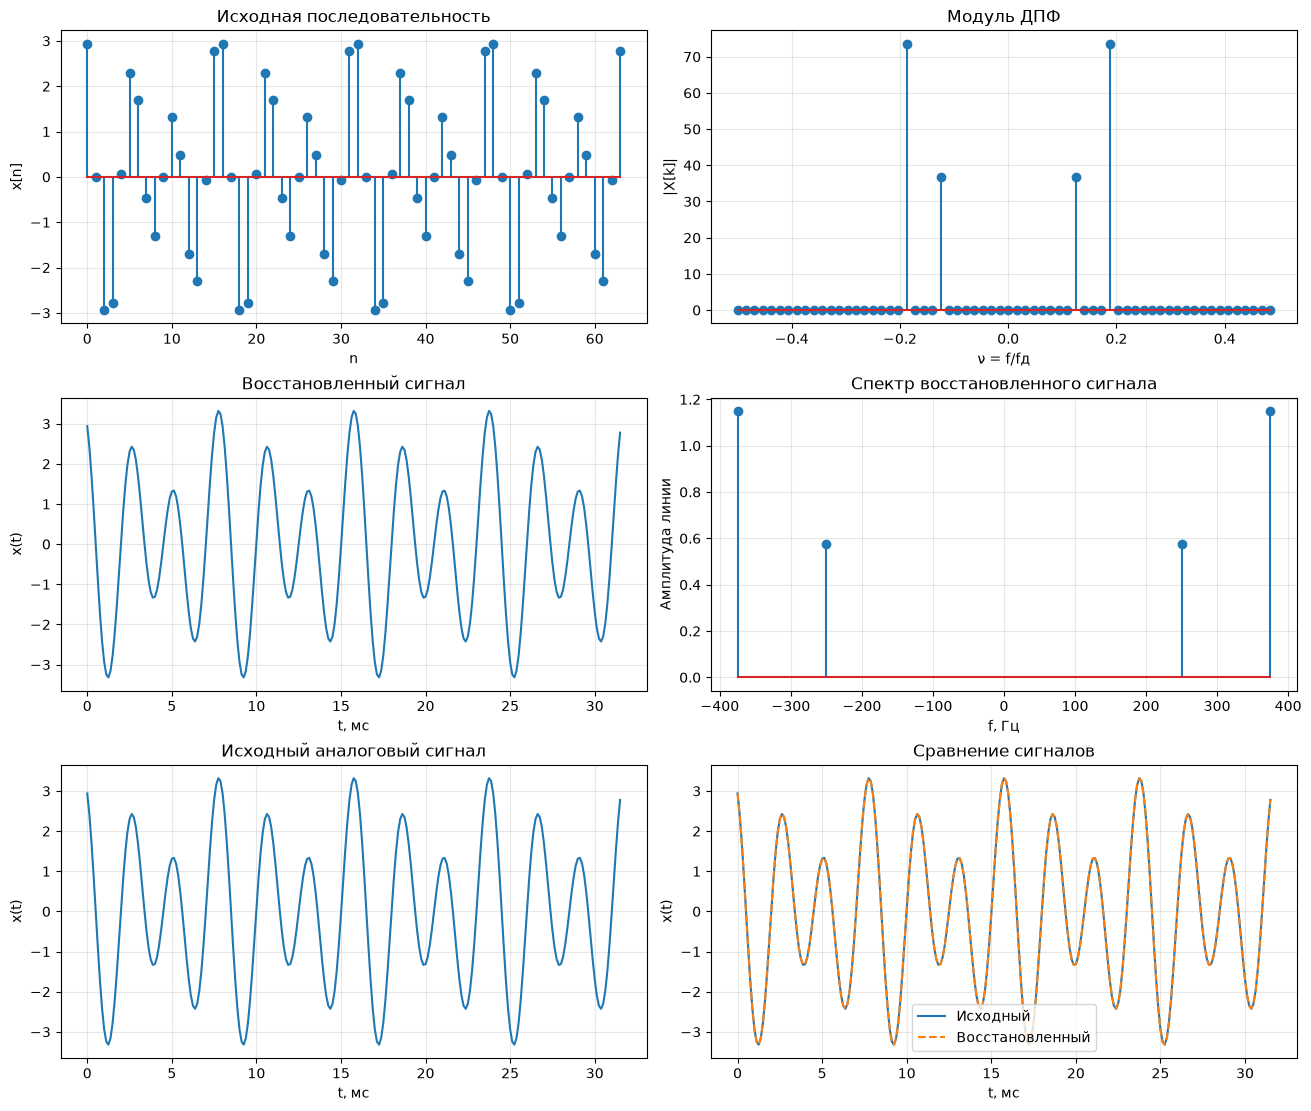

Максимальная ошибка восстановления: 3.241851231905457e-14


In [ ]:
t = np.arange(4*(N-1)+1)*T/4
Xa = np.fft.fftshift(X)
x_reconstructed_complex = np.exp(2j*np.pi*np.outer(t, k)/(N*T)) @ Xa/N
x_reconstructed = x_reconstructed_complex.real
x_original = A1*np.cos(2*np.pi*f1*t+np.pi/4)+A2*np.cos(2*np.pi*f2*t+np.pi/8)

fig, ax = plt.subplots(3, 2, figsize=(13, 11), constrained_layout=True)
ax[0, 0].stem(n, x)
ax[0, 0].set(xlabel='n', ylabel='x[n]', title='Исходная последовательность')
ax[0, 1].stem(nu, abs(Xa))
ax[0, 1].set(xlabel='ν = f/fд', ylabel='|X[k]|', title='Модуль ДПФ')
ax[1, 0].plot(t*1000, x_reconstructed)
ax[1, 0].set(xlabel='t, мс', ylabel='x(t)', title='Восстановленный сигнал')
ax[1, 1].stem(freq[mask], amplitude[mask])
ax[1, 1].set(xlabel='f, Гц', ylabel='Амплитуда линии', title='Спектр восстановленного сигнала')
ax[2, 0].plot(t*1000, x_original)
ax[2, 0].set(xlabel='t, мс', ylabel='x(t)', title='Исходный аналоговый сигнал')
ax[2, 1].plot(t*1000, x_original, label='Исходный')
ax[2, 1].plot(t*1000, x_reconstructed, '--', label='Восстановленный')
ax[2, 1].set(xlabel='t, мс', ylabel='x(t)', title='Сравнение сигналов')
ax[2, 1].legend()
plt.show()

error = np.max(abs(x_original-x_reconstructed))
print('Максимальная ошибка восстановления:', error)
assert len(t) == 253 and abs(t[-1]-(N-1)*T) < 1e-15
assert error < 1e-11
assert np.max(abs(x_reconstructed[::4]-x)) < 1e-11
assert np.max(abs(x_reconstructed_complex.imag)) < 1e-11

### 6. Объяснение результатов восстановления

Каждому коэффициенту ДПФ соответствует гармоника аналогового сигнала
с частотой $f_k=k/(NT)$ и комплексной амплитудой $C_k=X_a[k]/N$, поэтому модуль ДПФ в $N$ раз больше веса соответствующей линии
двустороннего аналогового спектра.

Исходный и восстановленный сигналы на графике совпадают, максимальная ошибка составляет примерно $3.3\cdot10^{-14}$.


Частоты обеих гармоник ниже частоты Найквиста $f_д/2=1000$ Гц,
и блок содержит целое число их периодов, поэтому заданный гармонический
сигнал восстанавливается с точностью вычислений.

### 7. Равенство Парсеваля

При выбранной нормировке ДПФ равенство Парсеваля имеет вид

$$\sum_{n=0}^{N-1}|x[n]|^2=\frac1N\sum_{k=0}^{N-1}|X[k]|^2.$$

In [ ]:
energy_time = np.sum(abs(x)**2)
energy_freq = np.sum(abs(X)**2)/N
power = energy_time/N

print('Энергия блока во временной области:', round(energy_time, 10))
print('Энергия блока в частотной области:', round(energy_freq, 10))
print('Средняя мощность:', round(power, 10))
print('Равенство Парсеваля выполнено:', np.isclose(energy_time, energy_freq))
assert abs(energy_time-energy_freq) < 1e-10
assert abs(energy_time-211.6) < 1e-10
assert abs(power-(A1**2+A2**2)/2) < 1e-12

Энергия блока во временной области: 211.6
Энергия блока в частотной области: 211.6
Средняя мощность: 3.30625
Равенство Парсеваля выполнено: True


Обе стороны равны 211.6. Равенство показывает, что энергия выбранного блока
одинакова при расчёте по временным отсчётам и по частотным коэффициентам
с учётом множителя $1/N$.


Средняя мощность периодической последовательности равна 3.30625.

## Выводы

В первой части рассчитаны импульсная характеристика и реакция рекурсивной
системы, свёртка и разностное уравнение дают одинаковый результат при достаточной
длине импульсной характеристики.

Система устойчива, поскольку модули полюсов
меньше единицы. По АЧХ установлено, что низкие частоты усиливаются,
а высокие преимущественно подавляются.

Во второй части рассчитаны ДПФ, ОДПФ, амплитудный и фазовый спектры.
Спектр содержит гармоники на частотах $\pm250$ и $\pm375$ Гц,
сигнал восстановлен по коэффициентам ДПФ с точностью вычислений.

Равенство Парсеваля подтверждено: энергия блока равна 211.6.